Step 1: Split the received signal as ref signal \& loc signal. Get the basic information including sample rate, starting time, etc.

The ref signal ends at index 58200000


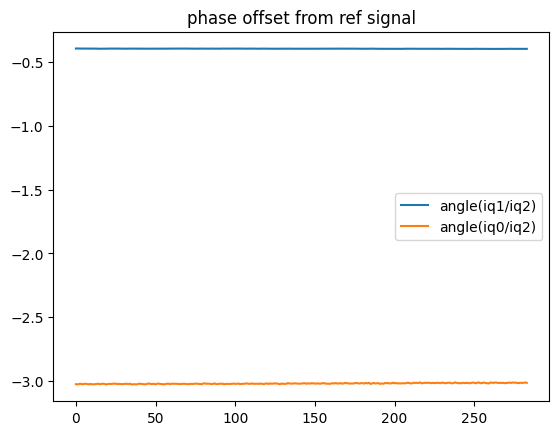

In [3]:
from preproc import preproc
import os
import scipy.io as sio
iq0_path = '/home/ishani/LeoPNT/USRP_data/1_10/time_20_44_freq_11_325G_bw_2.0M_1704943526.988162_inrx0.dat'
sample_rate = 2e6
date = "1_10"
start_time = 1704941134.9844222
# stop_time = start_time+40
fc = 11.325e9
loc_sig_idx = preproc(iq0_path, sample_rate)
# loc_sig_idx = 0

if not os.path.exists(date):
    os.makedirs(date)
# save sample_rate, date, start_time, loc_sig_idx to .mat file
sio.savemat(date + '/info.mat', {'IQ_Sample_file_0': iq0_path,'sample_rate': sample_rate, 'date': date, 'start_time': start_time, 'loc_sig_idx': loc_sig_idx})


Step 2: do the central tone tracking using matlab

In [ ]:
# first change the date in center_tone_track.m, then run the following commands
# matlab
# cd Starloc/
# center_tone_track($date)
# results saved to $date/peaks.mat

Step 3: connect the tracked central tones

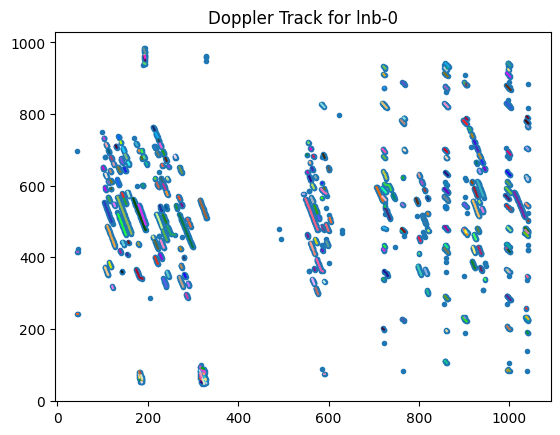

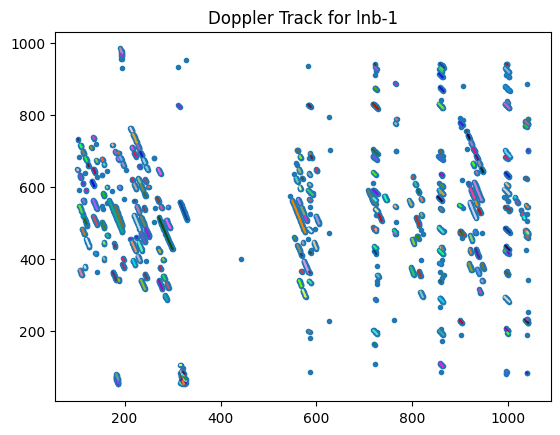

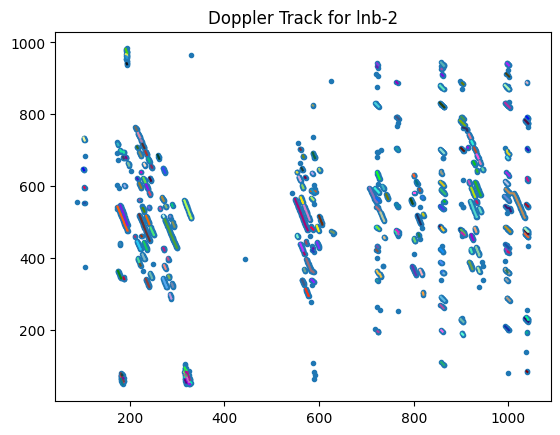

In [4]:
from sat_id import connect_doppler, doppler_sim
track_dict = connect_doppler(date)
output_tracks_file = date+"/output_tracks.mat"
sio.savemat(output_tracks_file, {'tracks_dict': track_dict})

Step 4: simulate doppler

In [3]:
sim_start_time = start_time
sim_end_time = stop_time
sat_dopp_dict, t_list = doppler_sim(date, '1_8/Starlink.tle', fc, sim_start_time, sim_end_time, 0.5)
output_doppler_file = date+"/output_doppler.mat"
output = {}
sio.savemat(output_doppler_file, {'sat_dopp_dict': sat_dopp_dict, 't_list': t_list})

number of Starlink satellites loaded 5299
1 STARLINK-1007
2 STARLINK-1008
3 STARLINK-1009
4 STARLINK-1010
5 STARLINK-1011
6 STARLINK-1012
7 STARLINK-1013
8 STARLINK-1014
9 STARLINK-1015
10 STARLINK-1017


11 STARLINK-1019
12 STARLINK-1020
13 STARLINK-1021
14 STARLINK-1024
15 STARLINK-1027
16 STARLINK-1028
17 STARLINK-1029
18 STARLINK-1030
19 STARLINK-1031
20 STARLINK-1032
21 STARLINK-1035
22 STARLINK-1036
23 STARLINK-1038
24 STARLINK-1039
25 STARLINK-1041
26 STARLINK-1042
27 STARLINK-1043
28 STARLINK-1046
29 STARLINK-1047
30 STARLINK-1048
31 STARLINK-1052
32 STARLINK-1053
33 STARLINK-1054
34 STARLINK-1055
35 STARLINK-1056
36 STARLINK-1057
37 STARLINK-1058
38 STARLINK-1059
39 STARLINK-1060
40 STARLINK-1061
41 STARLINK-1062
42 STARLINK-1063
43 STARLINK-1067
44 STARLINK-1068
45 STARLINK-1073
46 STARLINK-1084
47 STARLINK-1098
48 STARLINK-1099
49 STARLINK-1102
50 STARLINK-1103
51 STARLINK-1104
52 STARLINK-1106
53 STARLINK-1111
54 STARLINK-1112
55 STARLINK-1113
56 STARLINK-1114
57 STARLINK-1119
58 STARLINK-1121
59 STARLINK-1123
60 STARLINK-1128
61 STARLINK-1130 (DARKSAT)
62 STARLINK-1144
63 STARLINK-1071
64 STARLINK-1079
65 STARLINK-1082
66 STARLINK-1083
67 STARLINK-1091
68 STARLINK-1094
69 S